In [2]:
import pandas as pd
from IPython.display import display, HTML

In [2]:
all_results = pd.read_csv("all_results.csv",)

In [3]:
all_results

,dataset,model,run,training_time_s,sampling_time_s,cls_Real vs Real (baseline)_ROC-AUC,cls_Real vs Real (baseline)_Precision,cls_Real vs Real (baseline)_Recall,cls_Real vs Real (baseline)_F1,cls_Gen vs Real (TSTR)_ROC-AUC,...,qual_Val vs Gen_Coverage,spd_Real train_Sym.,spd_Real train_Pos. def.,spd_Real train_in M,spd_Generated train_Sym.,spd_Generated train_Pos. def.,spd_Generated train_in M,spd_Generated val_Sym.,spd_Generated val_Pos. def.,spd_Generated val_in M
0,BNCI2014002,diffeocfm,group_0,2522.4,0.8,0.8352,0.7179,0.7467,0.7320,0.7662,...,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,BNCI2014002,diffeocfm,group_1,1986.4,0.6,0.8097,0.6667,0.7941,0.7248,0.7532,...,0.9671,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,BNCI2014002,diffeocfm,group_2,2642.0,0.5,0.8318,0.6988,0.8056,0.7484,0.8082,...,0.9934,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,BNCI2014002,diffeocfm,group_3,2159.9,0.4,0.7964,0.7237,0.7432,0.7333,0.8032,...,0.9934,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,BNCI2014002,diffeocfm,group_4,2797.9,0.4,0.8315,0.7206,0.6901,0.7050,0.8294,...,0.9934,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,BNCI2014002,geodesiccfm,group_0,1807.7,1.4,0.8352,0.7179,0.7467,0.7320,0.8023,...,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,BNCI2014002,geodesiccfm,group_1,1313.2,1.3,0.8097,0.6667,0.7941,0.7248,0.7987,...,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,BNCI2014002,geodesiccfm,group_2,1811.7,1.3,0.8318,0.6988,0.8056,0.7484,0.7920,...,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,BNCI2014002,geodesiccfm,group_3,1311.1,1.4,0.7964,0.7237,0.7432,0.7333,0.8105,...,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
9,BNCI2014002,geodesiccfm,group_4,1813.8,1.3,0.8315,0.7206,0.6901,0.7050,0.8262,...,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [4]:
MODEL_ORDER  = ["diffeocfm", "geodesiccfm", "wrappedcfm", "wrappedcfm_with_prior"]
MODEL_LABELS = {"diffeocfm": "DiffeoCFM", "geodesiccfm": "GeodesicCFM",
                "wrappedcfm": "WrappedCFM", "wrappedcfm_with_prior": "WrappedCFM (prior)"}
DATASETS = sorted(all_results["dataset"].unique())

def make_table(df, metrics: dict, baseline_cols: dict = None) -> pd.DataFrame:
    """Build a mean±std table: rows=models, columns=metrics, one per dataset."""
    frames = {}
    for dataset in DATASETS:
        ds = df[df["dataset"] == dataset]
        rows = {}
        for model in MODEL_ORDER:
            m = ds[ds["model"] == model]
            row = {}
            for label, col in metrics.items():
                mean, std = m[col].mean(), m[col].std()
                row[label] = f"{mean:.3f} ± {std:.3f}"
            rows[MODEL_LABELS[model]] = row
        tbl = pd.DataFrame(rows).T
        if baseline_cols:
            baseline_row = {}
            for label, col in baseline_cols.items():
                val = ds[col].mean()
                baseline_row[label] = f"{val:.3f}"
            tbl.loc["— baseline —"] = baseline_row
        frames[dataset] = tbl
    return frames

## Classification metrics (TSTR & TRTS)

In [5]:
cls_metrics = {
    "TSTR ROC-AUC": "cls_Gen vs Real (TSTR)_ROC-AUC",
    "TSTR F1":      "cls_Gen vs Real (TSTR)_F1",
    "TRTS ROC-AUC": "cls_Real vs Gen (TRTS)_ROC-AUC",
    "TRTS F1":      "cls_Real vs Gen (TRTS)_F1",
}
cls_baselines = {
    "TSTR ROC-AUC": "cls_Real vs Real (baseline)_ROC-AUC",
    "TSTR F1":      "cls_Real vs Real (baseline)_F1",
    "TRTS ROC-AUC": "cls_Real vs Real (baseline)_ROC-AUC",
    "TRTS F1":      "cls_Real vs Real (baseline)_F1",
}

tables = make_table(all_results, cls_metrics, cls_baselines)
for dataset, tbl in tables.items():
    display(HTML(f"<h3>{dataset}</h3>"))
    display(tbl)

,TSTR ROC-AUC,TSTR F1,TRTS ROC-AUC,TRTS F1
DiffeoCFM,0.792 ± 0.031,0.685 ± 0.050,0.874 ± 0.029,0.766 ± 0.040
GeodesicCFM,0.806 ± 0.013,0.706 ± 0.017,0.892 ± 0.023,0.791 ± 0.019
WrappedCFM,0.811 ± 0.014,0.715 ± 0.020,0.855 ± 0.012,0.764 ± 0.024
WrappedCFM (prior),0.798 ± 0.017,0.718 ± 0.032,0.797 ± 0.040,0.687 ± 0.058
— baseline —,0.821,0.729,0.821,0.729


,TSTR ROC-AUC,TSTR F1,TRTS ROC-AUC,TRTS F1
DiffeoCFM,0.818 ± 0.002,0.729 ± 0.023,0.898 ± 0.013,0.816 ± 0.006
GeodesicCFM,0.816 ± 0.016,0.718 ± 0.008,0.889 ± 0.033,0.816 ± 0.013
WrappedCFM,0.796 ± 0.001,0.724 ± 0.008,0.831 ± 0.009,0.740 ± 0.012
WrappedCFM (prior),0.793 ± 0.028,0.701 ± 0.012,0.802 ± 0.031,0.704 ± 0.039
— baseline —,0.807,0.727,0.807,0.727


,TSTR ROC-AUC,TSTR F1,TRTS ROC-AUC,TRTS F1
DiffeoCFM,0.968 ± nan,0.906 ± nan,0.978 ± nan,0.916 ± nan
GeodesicCFM,0.980 ± nan,0.929 ± nan,0.979 ± nan,0.920 ± nan
WrappedCFM,0.980 ± nan,0.930 ± nan,0.979 ± nan,0.919 ± nan
WrappedCFM (prior),0.981 ± nan,0.925 ± nan,0.979 ± nan,0.921 ± nan
— baseline —,0.982,0.935,0.982,0.935


## Quality metrics (Train vs Gen)

In [6]:
qual_metrics = {
    "Precision": "qual_Train vs Gen_Precision",
    "Recall":    "qual_Train vs Gen_Recall",
    "Density":   "qual_Train vs Gen_Density",
    "Coverage":  "qual_Train vs Gen_Coverage",
}
qual_baselines = {
    "Precision": "qual_Train vs Val (baseline)_Precision",
    "Recall":    "qual_Train vs Val (baseline)_Recall",
    "Density":   "qual_Train vs Val (baseline)_Density",
    "Coverage":  "qual_Train vs Val (baseline)_Coverage",
}

tables = make_table(all_results, qual_metrics, qual_baselines)
for dataset, tbl in tables.items():
    display(HTML(f"<h3>{dataset}</h3>"))
    display(tbl)

,Precision,Recall,Density,Coverage
DiffeoCFM,0.496 ± 0.032,0.986 ± 0.001,0.276 ± 0.040,0.760 ± 0.036
GeodesicCFM,0.714 ± 0.028,0.975 ± 0.002,0.576 ± 0.081,0.942 ± 0.020
WrappedCFM,0.718 ± 0.016,0.972 ± 0.003,0.607 ± 0.077,0.939 ± 0.012
WrappedCFM (prior),0.710 ± 0.035,0.973 ± 0.006,0.554 ± 0.080,0.924 ± 0.018
— baseline —,0.993,0.992,0.945,0.951


,Precision,Recall,Density,Coverage
DiffeoCFM,0.645 ± 0.002,0.956 ± 0.007,0.335 ± 0.027,0.789 ± 0.004
GeodesicCFM,0.884 ± 0.006,0.931 ± 0.009,0.934 ± 0.011,0.989 ± 0.001
WrappedCFM,0.909 ± 0.023,0.915 ± 0.001,1.072 ± 0.095,0.992 ± 0.004
WrappedCFM (prior),0.891 ± 0.002,0.922 ± 0.002,0.974 ± 0.032,0.978 ± 0.010
— baseline —,0.979,0.993,1.004,0.998


,Precision,Recall,Density,Coverage
DiffeoCFM,0.925 ± nan,0.964 ± nan,0.698 ± nan,0.958 ± nan
GeodesicCFM,0.975 ± nan,0.975 ± nan,0.949 ± nan,0.994 ± nan
WrappedCFM,0.973 ± nan,0.976 ± nan,0.948 ± nan,0.994 ± nan
WrappedCFM (prior),0.975 ± nan,0.976 ± nan,0.945 ± nan,0.995 ± nan
— baseline —,0.975,0.981,0.991,1.000


## Training & sampling time

In [20]:
time_metrics = {
    "Training time (s)": "training_time_s",
    "Sampling time (s)": "sampling_time_s",
}

tables = make_table(all_results, time_metrics)
for dataset, tbl in tables.items():
    display(HTML(f"<h3>{dataset}</h3>"))
    display(tbl)

,Training time (s),Sampling time (s)
DiffeoCFM,2421.720 ± 338.461,0.540 ± 0.167
GeodesicCFM,1611.500 ± 273.278,1.340 ± 0.055
WrappedCFM,2354.740 ± 327.387,2.120 ± 0.466
WrappedCFM (prior),2874.480 ± 502.205,1.440 ± 0.114


,Training time (s),Sampling time (s)
DiffeoCFM,746.350 ± 5.869,0.450 ± 0.071
GeodesicCFM,1805.100 ± 28.143,3.850 ± 2.616
WrappedCFM,1688.150 ± 42.921,1.750 ± 0.071
WrappedCFM (prior),2402.700 ± 30.406,1.500 ± 0.000


## Condition-number sweep (WG mixture)

Metrics vs the condition number $\kappa$ of the class centers, from `synthetic_summary.csv` (mean ± std over 5 seeds; per-seed values live in the cluster logs). $\kappa \ge 10^3$ runs use gradient clipping + EMA; $\kappa \in \{10, 100\}$ predate them (rerun for homogeneity). Reading guide:

- **(a)** W2 for all models (log scale); the dashed gray curve is the *predicted* DiffeoCFM conditional anisotropy $\operatorname{sinhc}^2(\ln\kappa/2)$ at $t=1$ (right axis).
- **(b)** Same W2 zoomed on the Riemannian models: DiffeoCFM degrades monotonically with $\kappa$ and keeps a large seed-variance at $\kappa=10^4$ even with clipping+EMA (seed-level learning failures); WrappedCFM and GeodesicCFM stay flat and tight.
- **(c)** EuclideanCFM's SPD violation: 100% → 1.8% of generated samples SPD.
- **(d)** Log-likelihood. Only comparable **across methods at fixed $\kappa$** (the dataset geometry changes with $\kappa$), not along the x-axis.

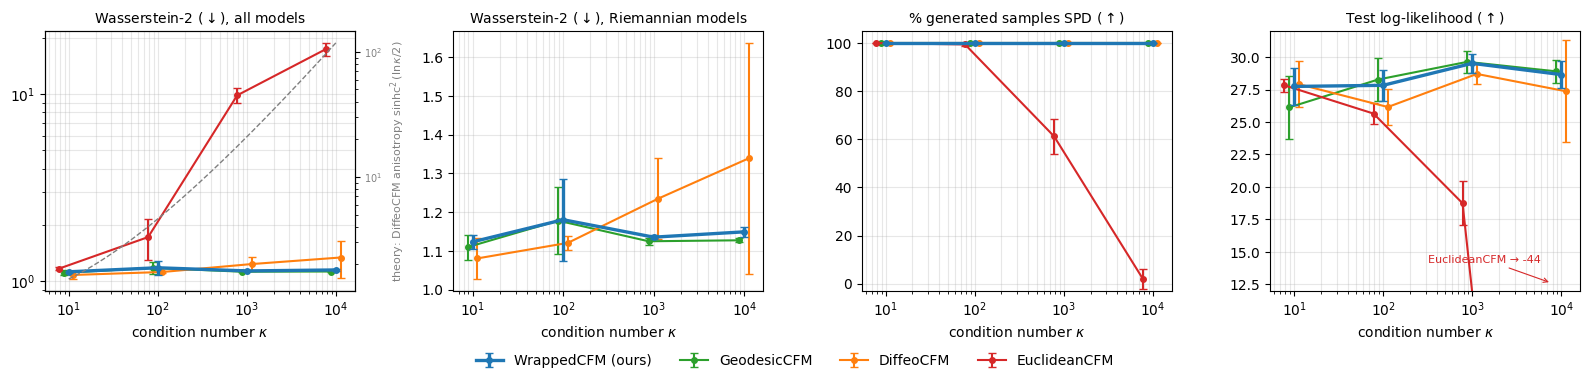

In [3]:
import numpy as np
import matplotlib.pyplot as plt

summary = pd.read_csv("synthetic_summary.csv", skipinitialspace=True)
for c in ("dataset", "model"):
    summary[c] = summary[c].str.strip()

wg = summary[summary["dataset"].str.startswith("wg_mixture_k")].copy()
wg["kappa"] = wg["dataset"].str.replace("wg_mixture_k", "", regex=False).astype(float)
wg = wg.sort_values("kappa")

SWEEP_MODELS = ["wrappedcfm", "geodesiccfm", "diffeocfm", "euclideancfm"]
RIEMANNIAN = ["wrappedcfm", "geodesiccfm", "diffeocfm"]
STYLE = {
    "wrappedcfm":   dict(label="WrappedCFM (ours)", color="tab:blue",   lw=2.4, zorder=5),
    "geodesiccfm":  dict(label="GeodesicCFM",       color="tab:green",  lw=1.5),
    "diffeocfm":    dict(label="DiffeoCFM",         color="tab:orange", lw=1.5),
    "euclideancfm": dict(label="EuclideanCFM",      color="tab:red",    lw=1.5),
}
# small multiplicative x-offsets so error bars at the same kappa don't overlap
OFFSETS = {"wrappedcfm": 1.0, "geodesiccfm": 0.88, "diffeocfm": 1.13, "euclideancfm": 0.78}


def draw(ax, models, mcol, scol):
    for model in models:
        m = wg[wg["model"] == model]
        ax.errorbar(m["kappa"] * OFFSETS[model], m[mcol], yerr=m[scol],
                    marker="o", ms=4, capsize=3, **STYLE[model])
    ax.set_xscale("log")
    ax.set_xlabel(r"condition number $\kappa$")
    ax.grid(alpha=0.3, which="both")


fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))

# (a) W2, all models (log scale) + theoretical DiffeoCFM anisotropy at t=1
draw(axes[0], SWEEP_MODELS, "w2_mean", "w2_std")
axes[0].set_yscale("log")
axes[0].set_title(r"Wasserstein-2 ($\downarrow$), all models", fontsize=10)
kk = np.logspace(1, 4, 200)
half = np.log(kk) / 2
ax2 = axes[0].twinx()
ax2.plot(kk, (np.sinh(half) / half) ** 2, ls="--", color="gray", lw=1)
ax2.set_yscale("log")
ax2.set_ylabel(r"theory: DiffeoCFM anisotropy $\operatorname{sinhc}^2(\ln\kappa/2)$",
               color="gray", fontsize=8)
ax2.tick_params(axis="y", labelcolor="gray", labelsize=7)

# (b) W2, Riemannian models only (linear zoom)
draw(axes[1], RIEMANNIAN, "w2_mean", "w2_std")
axes[1].set_title(r"Wasserstein-2 ($\downarrow$), Riemannian models", fontsize=10)

# (c) % SPD
draw(axes[2], SWEEP_MODELS, "pct_spd_mean", "pct_spd_std")
axes[2].set_ylim(-3, 105)
axes[2].set_title(r"% generated samples SPD ($\uparrow$)", fontsize=10)

# (d) LL, zoomed to the Riemannian range; EuclideanCFM leaves the axis at k=1e4
draw(axes[3], SWEEP_MODELS, "ll_mean", "ll_std")
axes[3].set_ylim(12, 32)
axes[3].set_title(r"Test log-likelihood ($\uparrow$)", fontsize=10)
e4 = wg[(wg["model"] == "euclideancfm") & (wg["kappa"] == 10000)]["ll_mean"].iloc[0]
axes[3].annotate(f"EuclideanCFM → {e4:.0f}", xy=(10000 * OFFSETS["euclideancfm"], 12.6),
                 xytext=(320, 14.2), fontsize=8, color="tab:red",
                 arrowprops=dict(arrowstyle="->", color="tab:red", lw=0.8))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.07), frameon=False)
fig.tight_layout()
#fig.savefig("wg_mixture_condition_sweep.pdf", bbox_inches="tight")
plt.show()

## Paper presentation: two stress axes + cross-regime table

**Figure 1 ("two stress axes")** — each baseline's geometric shortcut has a characteristic failure axis:
GeodesicCFM (Dirac geodesic paths) and EuclideanCFM degrade with **target complexity** (panel a, swiss-roll dimension);
DiffeoCFM (fixed tangent chart) and EuclideanCFM degrade with **conditioning** (panel b, WG-mixture $\kappa$).
WrappedCFM is the only method flat on both axes.

**Table 1 (cross-regime)** — W2 on one representative dataset per regime, worst-case %SPD across all benchmarks, and the
robustness capstone: *worst-case W2 ratio vs the best method, across all benchmarks*
(WrappedCFM ≈ 1.12×, DiffeoCFM ≈ 1.19×, GeodesicCFM ≈ 2.03×, EuclideanCFM ≈ 15×).
Bold = mean within one std of the column best; ✗ = W2 > 1.5× the column best. The cell also prints the LaTeX (booktabs) version.

⚠️ Regime homogeneity: the swiss-roll/figure8 rows and WG $\kappa\in\{10,100\}$ rows currently predate
gradient clipping + EMA (the $\kappa \ge 10^3$ rows have them). Rerun those before the paper version.

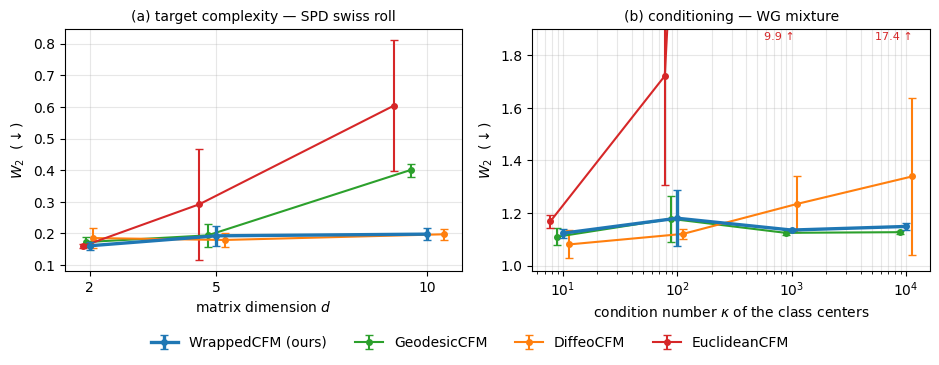

In [4]:
# Figure 1: two stress axes. (a) target complexity (swiss roll, d = 2/5/10),
# (b) conditioning (WG mixture, kappa = 10..1e4). WrappedCFM is the only
# method flat on both. EuclideanCFM exits panel (b) at kappa >= 1e3 (annotated).
summary = pd.read_csv("synthetic_summary.csv", skipinitialspace=True)
for c in ("dataset", "model"):
    summary[c] = summary[c].str.strip()

MODELS = ["wrappedcfm", "geodesiccfm", "diffeocfm", "euclideancfm"]
STYLE = {
    "wrappedcfm":   dict(label="WrappedCFM (ours)", color="tab:blue",   lw=2.4, zorder=5),
    "geodesiccfm":  dict(label="GeodesicCFM",       color="tab:green",  lw=1.5),
    "diffeocfm":    dict(label="DiffeoCFM",         color="tab:orange", lw=1.5),
    "euclideancfm": dict(label="EuclideanCFM",      color="tab:red",    lw=1.5),
}
# small multiplicative x-offsets so error bars at the same x don't overlap
OFF = {"wrappedcfm": 1.0, "geodesiccfm": 0.96, "diffeocfm": 1.04, "euclideancfm": 0.92}

SWISS_DIMS = {"swiss_roll": 2, "swiss_roll_dim_5": 5, "swiss_roll_dim_10": 10}
wg = summary[summary["dataset"].str.startswith("wg_mixture_k")].copy()
wg["kappa"] = wg["dataset"].str.replace("wg_mixture_k", "", regex=False).astype(float)
sw = summary[summary["dataset"].isin(SWISS_DIMS)].copy()
sw["dim"] = sw["dataset"].map(SWISS_DIMS)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for model in MODELS:
    m = sw[sw["model"] == model].sort_values("dim")
    axes[0].errorbar(m["dim"] * OFF[model], m["w2_mean"], yerr=m["w2_std"],
                     marker="o", ms=4, capsize=3, **STYLE[model])
    m = wg[wg["model"] == model].sort_values("kappa")
    axes[1].errorbar(m["kappa"] * OFF[model] ** 3, m["w2_mean"], yerr=m["w2_std"],
                     marker="o", ms=4, capsize=3, **STYLE[model])

axes[0].set_xlabel(r"matrix dimension $d$")
axes[0].set_xticks(list(SWISS_DIMS.values()))
axes[0].set_title("(a) target complexity — SPD swiss roll", fontsize=10)

axes[1].set_xscale("log")
axes[1].set_ylim(0.98, 1.9)  # linear zoom: EuclideanCFM exits the axis
axes[1].set_xlabel(r"condition number $\kappa$ of the class centers")
axes[1].set_title("(b) conditioning — WG mixture", fontsize=10)
for k, w2v in wg[(wg["model"] == "euclideancfm") & (wg["kappa"] >= 1e3)][["kappa", "w2_mean"]].values:
    axes[1].annotate(f"{w2v:.1f} ↑", xy=(k * 0.92**3, 1.86), fontsize=8,
                     color="tab:red", ha="center")

for ax in axes:
    ax.set_ylabel(r"$W_2$  ($\downarrow$)")
    ax.grid(alpha=0.3, which="both")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout()
# fig.savefig("two_stress_axes.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Table 1: cross-regime W2 table + worst-case robustness column.
# Bold = mean within one std of the best method's mean (per column).
# "✗" = failure: W2 > 1.5x the column best. LaTeX printed below for the paper.
summary = pd.read_csv("synthetic_summary.csv", skipinitialspace=True)
for c in ("dataset", "model"):
    summary[c] = summary[c].str.strip()

MODELS = ["wrappedcfm", "geodesiccfm", "diffeocfm", "euclideancfm"]
LABELS = {"wrappedcfm": "WrappedCFM (ours)", "geodesiccfm": "GeodesicCFM",
          "diffeocfm": "DiffeoCFM", "euclideancfm": "EuclideanCFM"}
REGIMES = {
    "Figure-8 (easy)": "figure8",
    "Swiss-roll d=10 (complex)": "swiss_roll_dim_10",
    "WG mixture k=1e4 (ill-cond.)": "wg_mixture_k10000",
}
FAIL_FACTOR = 1.5

# worst-case ratio and worst-case %SPD are computed across ALL datasets
best_per_ds = summary.groupby("dataset")["w2_mean"].transform("min")
summary["w2_ratio"] = summary["w2_mean"] / best_per_ds
worst_ratio = summary.groupby("model")["w2_ratio"].max()
worst_ratio_ds = summary.loc[summary.groupby("model")["w2_ratio"].idxmax()].set_index("model")["dataset"]
worst_spd = summary.groupby("model")["pct_spd_mean"].min()


def fmt_cell(ds, model, latex=False):
    col = summary[summary["dataset"] == ds]
    r = col[col["model"] == model].iloc[0]
    b = col.loc[col["w2_mean"].idxmin()]
    txt = f"{r.w2_mean:.3f} ± {r.w2_std:.3f}"
    is_best = r.w2_mean <= b.w2_mean + b.w2_std
    is_fail = r.w2_mean > FAIL_FACTOR * b.w2_mean
    if latex:
        txt = txt.replace("±", r"$\pm$")
        if is_best:
            txt = r"\textbf{" + txt + "}"
        if is_fail:
            txt += r" $^{\times}$"
    else:
        if is_best:
            txt = "**" + txt + "**"
        if is_fail:
            txt += " ✗"
    return txt


rows = []
for model in MODELS:
    row = {"Method": LABELS[model]}
    for col_label, ds in REGIMES.items():
        row[col_label] = fmt_cell(ds, model)
    row["%SPD (worst)"] = f"{worst_spd[model]:.1f}"
    row["Worst-case W2 vs best"] = f"{worst_ratio[model]:.2f}x  ({worst_ratio_ds[model]})"
    rows.append(row)
display(pd.DataFrame(rows).set_index("Method"))

# LaTeX version (booktabs)
lines = [r"\begin{tabular}{l" + "c" * (len(REGIMES) + 2) + "}", r"\toprule",
         "Method & " + " & ".join(REGIMES)
         + r" & \%SPD (worst) & Worst-case $W_2$ ratio \\", r"\midrule"]
for model in MODELS:
    cells = [LABELS[model]] + [fmt_cell(ds, model, latex=True) for ds in REGIMES.values()]
    cells += [f"{worst_spd[model]:.1f}", f"{worst_ratio[model]:.2f}" + r"$\times$"]
    lines.append(" & ".join(cells) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}"]
print("\n".join(lines))